In [1]:
import torchtext; torchtext.disable_torchtext_deprecation_warning()
from torchtext.data.utils import get_tokenizer

In [2]:
filepath = '../dataset/images/1034276567_49bb87c51c.jpg'

In [3]:
tokenizer = get_tokenizer('basic_english')

def remove_recurring_words(text, n=2):
    words = tokenizer(text)
    results = []
    for i, word in enumerate(words):
        if (i+n < len(words)):
            if (word != words[i+n]):
                results.append(word)
        else:
            results.append(word)
            
    return " ".join(results)

word = "seorang pria dengan jaket kuning dan topi merah muda dan topi merah muda dan topi merah muda dan topi merah muda dan topi merah muda dan topi"
for i in range(4):
    word = remove_recurring_words(word, n=i+1)
    
word

'seorang pria dengan jaket kuning merah muda dan topi'

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


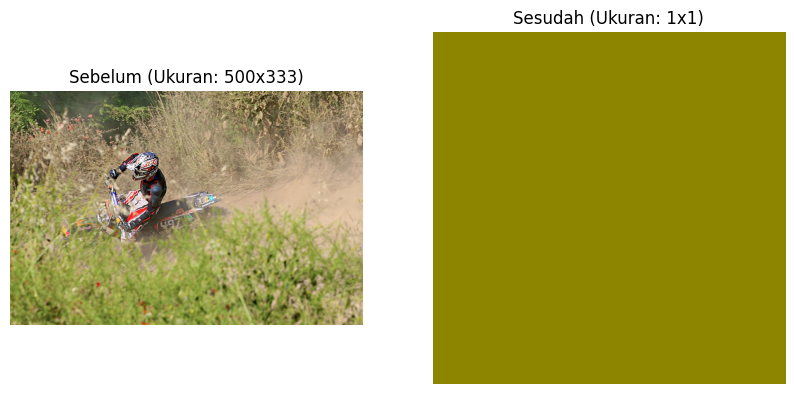

In [4]:
import timm.data
from PIL import Image
import matplotlib.pyplot as plt
from dataset import get_transforms

cnn_backbone = 'efficientnetv2_rw_s.ra2_in1k'

transforms = get_transforms(True)

image_path = '../dataset/images/3576250302_14779632bd.jpg'
image = Image.open(image_path).convert("RGB")
transformed_image = transforms(image)

if transformed_image.dim() == 3:  # Check if the image has three dimensions
    transformed_image = transformed_image.permute(1, 2, 0)  # Change from CxHxW to HxWxC

fig, ax = plt.subplots(1, 2, figsize=(10, 5))  # Adjust the figure size as needed

# Display the original image
original_size = image.size  # Get the size of the original image
ax[0].imshow(image)
ax[0].set_title(f'Sebelum (Ukuran: {original_size[0]}x{original_size[1]})')
ax[0].axis('off')

# Display the transformed image
transformed_size = transformed_image.shape[:2]  # Get the size of the transformed image
ax[1].imshow(transformed_image)
ax[1].set_title(f'Sesudah (Ukuran: {transformed_size[1]}x{transformed_size[0]})')
ax[1].axis('off')

# Show the plot
plt.show()

In [5]:
# init directory and file path
root_path = '../'
data_root_path = f"{root_path}dataset"
text_dataset = f"{data_root_path}/text/Flickr8k.token.bahasa.txt"
clean_text_dataset = f"{data_root_path}/text/Flickr8k.token.bahasa.clean.txt"

train_file = data_root_path + "/text/" + "Flickr_8k.trainImages.txt"
val_file = data_root_path +  "/text/" + "Flickr_8k.devImages.txt"
test_file = data_root_path + "/text/" + "Flickr_8k.testImages.txt"

In [6]:
# Clean dataset
import os
from dataset import clean_data

if not os.path.exists(clean_text_dataset):
    clean_data(text_dataset, clean_text_dataset, data_root_path)

In [10]:
import timm
from torchsummary import summary

device = 'cuda'
model = timm.create_model('timm/efficientnetv2_rw_s.ra2_in1k', pretrained=True)
model.to(device)

summary(model, input_size=(3, 288, 288))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 24, 144, 144]             648
          Identity-2         [-1, 24, 144, 144]               0
              SiLU-3         [-1, 24, 144, 144]               0
    BatchNormAct2d-4         [-1, 24, 144, 144]              48
            Conv2d-5         [-1, 24, 144, 144]           5,184
          Identity-6         [-1, 24, 144, 144]               0
              SiLU-7         [-1, 24, 144, 144]               0
    BatchNormAct2d-8         [-1, 24, 144, 144]              48
          Identity-9         [-1, 24, 144, 144]               0
           Conv2d-10         [-1, 24, 144, 144]             576
         Identity-11         [-1, 24, 144, 144]               0
         Identity-12         [-1, 24, 144, 144]               0
   BatchNormAct2d-13         [-1, 24, 144, 144]              48
         Identity-14         [-1, 24, 1

In [20]:

import pandas as pd


# def count_words(string):
#     return len(string.split())

# dfc = pd.read_csv(clean_text_dataset, delimiter='\t', names=["filename", 'captions'])

# # # Apply the function to each row in the column and find the index of the row with the most words
# dfc['word_count'] = dfc['captions'].apply(count_words)
# row_with_most_words = dfc['word_count'].idxmax()
# # Print the row with the most words
# print("Row with the most words:", row_with_most_words)
# print("Count:", dfc.loc[row_with_most_words]['word_count'])
# print("Content:", dfc.loc[row_with_most_words, 'captions'])

# sorted_df = dfc.sort_values(by='word_count', ascending=False)
# sorted_df[:100]

In [8]:
# from dataset import create_text_data, split_data
# from collections import Counter

# dataframe, vocab, counter = create_text_data(clean_text_dataset, tokenizer=tokenizer)

# def list_top_words(counter, vocab, num_words=10):
#     # Extract the most frequent words from the Counter
    
#     filtered_tokens = {word: freq for word, freq in counter.items() if word != '.'}
    
#     # Extract the most frequent words from the filtered Counter
#     most_common_tokens = Counter(filtered_tokens).most_common(num_words)
    
#     # Prepare data for the DataFrame
#     data = {
#         'Word': [word for word, freq in most_common_tokens],
#         'Frequency': [freq for word, freq in most_common_tokens]
#     }

#     # Create a DataFrame
#     df = pd.DataFrame(data)
#     return df

# top_words_df = list_top_words(counter, vocab)

# def plot_histogram(dataframe):
#     # Set up the figure and axis
#     plt.figure(figsize=(8, 6))
    
#     # Create a bar chart
#     plt.bar(dataframe['Word'], dataframe['Frequency'], color='skyblue')
    
#     # Add title and labels
#     plt.title('10 Kata dengan Frekuensi Paling Tinggi')
#     plt.xlabel('Kata')
#     plt.ylabel('Frekuensi')
    
#     # Add value labels on each bar
#     for i, freq in enumerate(dataframe['Frequency']):
#         plt.text(i, freq + 0.5, str(freq), ha = 'center', va = 'bottom')
    
#     # Show the plot
#     plt.xticks(rotation=45)  # Rotate the x labels to make them more readable
#     plt.tight_layout()  # Adjust layout to make room for the rotated x-axis labels
#     plt.show()

# # Assuming 'top_words_df' is already defined
# plot_histogram(top_words_df)

In [9]:
from dataset import create_text_data, split_data
import torch

dataframe, vocab = create_text_data(clean_text_dataset, tokenizer=tokenizer)

# split data train, val, test
train_df, val_df, test_df = split_data(dataframe, train_file, val_file, test_file)

# Hyperparameters
d_model = 512
fc_dim = 2048
vocab_size = len(vocab)
num_layers = 1
n_head = 4
max_seq_len = 25
image_size = 288
num_epochs = 12
dropout = 0.1
cnn_model = 'efficientnetv2_rw_s.ra2_in1k'
batch_size = 32
num_workers = 4
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
# Prepare transforms
cnn_backbone = 'efficientnetv2_rw_s.ra2_in1k'
dummy_cnn = timm.create_model(cnn_backbone, pretrained=False)
data_config = timm.data.resolve_model_data_config(dummy_cnn)
train_transforms =  timm.data.create_transform(**data_config, is_training=True)
val_test_transforms =  timm.data.create_transform(**data_config, is_training=False)

In [10]:
vocab_size

6070

In [21]:
print(f"Training data: {len(train_df)}")
print(f"Validation data: {len(val_df)}")
print(f"Test data: {len(test_df)}")

Training data: 6000
Validation data: 1000
Test data: 1000


In [23]:
print(test_df.iloc[1])

image_filename                                                                                                                                                                                                                                                               106490881_5a2dd9b7bd.jpg
captions          [anak laki-laki dengan celana pendek renang birunya di pantai., anak laki-laki tersenyum di depan kamera di pantai., anak laki-laki dengan celana renang berjalan dengan tangan terentang di pantai., Anak-anak bermain di pantai ., Anak laki-laki sedang bermain di tepi lautan.]
Name: 48, dtype: object


In [ ]:
from dataset import Flickr8kDataset
from data_loader import get_loader

# Init dataset
train_dataset = Flickr8kDataset(data_root_path, train_df, vocab, tokenizer, max_seq_len, train_transforms)
val_dataset = Flickr8kDataset(data_root_path, val_df, vocab, tokenizer, max_seq_len, val_test_transforms)
test_dataset = Flickr8kDataset(data_root_path, test_df, vocab, tokenizer, max_seq_len, val_test_transforms)

# Init loader
train_loader, val_loader, test_loader = get_loader(train_dataset, val_dataset, test_dataset, batch_size, num_workers)

In [ ]:
data = next(iter(test_loader))

In [ ]:
data['image_filename']

In [ ]:
# Initialize an empty list to store the batches
first_ten_batches = []

# Iterate over the DataLoader
for i, data in enumerate(train_loader):
    first_ten_batches.append(data)  # Store the batch
    if i == 9:  # Check if 10 batches have been collected
        break

In [ ]:
from model import ImageCaptioningModel
import datetime, time
import torch.nn as nn
import torch.optim as optim

model = ImageCaptioningModel(
    cnn_backbone=cnn_model,
    image_size=image_size,
    d_model=d_model,
    fc_dim=fc_dim,
    vocab_size=vocab_size,
    num_layers=num_layers,
    n_head=n_head,
    max_seq_length=max_seq_len,
    dropout=dropout
).to(device)


 # Set model name based on current datetime
current_time = datetime.datetime.now()
formatted_time = current_time.strftime('%Y%m%d_%H%M')
model_save_path = f'saved_model/'

checkpoint_path = 'checkpoints/'

# For optimizer
initial_lr = 0.001
final_lr = 0.0001
total_steps = len(train_loader) * num_epochs
warmup_steps = total_steps // 10  # Example: 10% of total steps as warmup

criterion = nn.CrossEntropyLoss(ignore_index=vocab['<PAD>'])
optimizer = optim.Adam(model.parameters(), lr=initial_lr)

# Initialize or load checkpoint
start_epoch = 0
best_val_loss = float('inf')
patience_counter = 0

In [ ]:
from utils import find_latest_checkpoint, save_model, update_learning_rate
from train import train, validate

latest_checkpoint = find_latest_checkpoint(checkpoint_path)

# Main training loop
for epoch in range(start_epoch, num_epochs):
    step = epoch * len(train_loader)
    update_learning_rate(optimizer, step, warmup_steps, initial_lr, final_lr)
    
    start_time = time.time()
    train_loss = train(model, train_loader, optimizer, criterion, device, vocab_size, epoch)
    val_loss = validate(model, val_loader, criterion, device, vocab_size, epoch)
    end_time = time.time()
    
    epoch_duration = end_time - start_time
    print(f'Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Validation Loss: {val_loss:.4f}, Time: {epoch_duration:.2f} sec')
    
    # Save checkpoint
    checkpoint_data = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'val_loss': val_loss
        }
    checkpoint_filename = f"{checkpoint_path}checkpoint_epoch_{epoch+1}.pth"
    torch.save(checkpoint_data, checkpoint_filename)
    print(f"Checkpoint saved for epoch {epoch+1}")
    
    # Early stopping logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        print(f"Improved validation loss at epoch {epoch+1}")
    else:
        patience_counter += 1
        print(f"No improvement in validation loss for {patience_counter} epochs.")

save_model(model, model_save_path)
print(f'Model saved successfully at {model_save_path}')

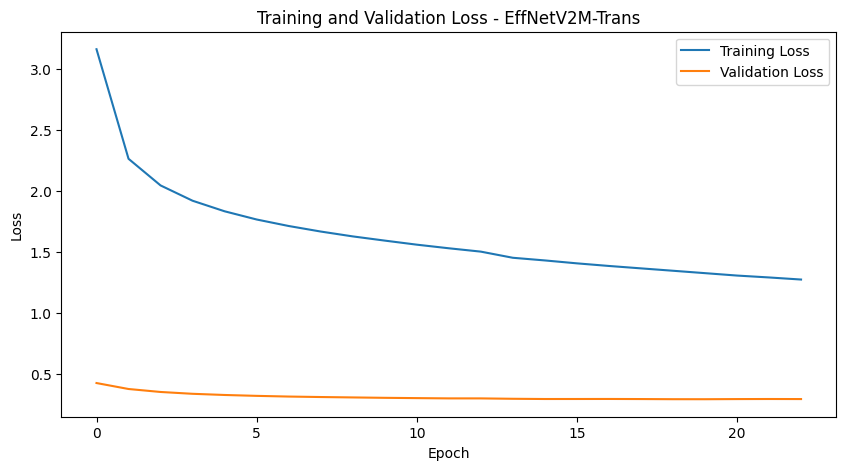

In [14]:
from utils import plot_losses

dir = 'checkpoints/512_4_m/'

df = plot_losses(dir, title='EffNetV2M-Trans')

In [16]:
# Filter hanya untuk epoch genap
df_even = df[df['Epoch'] % 2 == 1]

# Tambahkan 1 ke setiap nilai epoch
df_even['Epoch'] = df_even['Epoch'] + 1

df

C:\Users\Teguh\AppData\Local\Temp\ipykernel_15572\797221996.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_even['Epoch'] = df_even['Epoch'] + 1


,Epoch,Train Loss,Validation Loss,Epoch Duration
0,0,3.163546,0.426860,513.244177
1,1,2.265302,0.377971,500.434914
2,2,2.046930,0.353616,502.470523
3,3,1.921418,0.338604,510.167005
4,4,1.834867,0.328975,513.194673
5,5,1.767655,0.321739,504.339293
6,6,1.714313,0.316042,493.194739
7,7,1.668941,0.312146,485.757804
8,8,1.629116,0.308847,483.917046
9,9,1.594587,0.305637,483.739425
